In [1]:
import pandas as pd

df = pd.read_csv("turkiye_81_il_yasam_profilleri.csv")   

print(df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum())
print(df.describe())

(81, 11)
   Plaka_Kodu           Sehir              Bolge    Nufus  \
0           1           Adana            Akdeniz  2270298   
1           2        Adıyaman  Güneydoğu Anadolu   604978   
2           3  Afyonkarahisar                Ege   751344   
3           4            Ağrı       Doğu Anadolu   511238   
4           5          Amasya          Karadeniz   339529   

   Kisi_Basi_GSYH_Bin_TL  Universite_Mezunu_Orani  Issizlik_Orani  \
0                    255                     17.2            11.4   
1                    175                     14.1            11.8   
2                    240                     15.6             7.2   
3                    125                     10.4            13.6   
4                    235                     17.5             7.6   

   Yasam_Memnuniyeti_Endeksi  Konut_Kira_Endeksi  Saglik_Endeksi  \
0                       52.1                54.0            68.5   
1                       55.4                42.5            58.0   
2    

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("turkiye_81_il_yasam_profilleri.csv", encoding="utf-8-sig")
print(df.shape)
df.head()

(81, 11)


,Plaka_Kodu,Sehir,Bolge,Nufus,Kisi_Basi_GSYH_Bin_TL,Universite_Mezunu_Orani,Issizlik_Orani,Yasam_Memnuniyeti_Endeksi,Konut_Kira_Endeksi,Saglik_Endeksi,Cevre_Altyapi_Endeksi
0,1,Adana,Akdeniz,2270298,255,17.2,11.4,52.1,54.0,68.5,61.2
1,2,Adıyaman,Güneydoğu Anadolu,604978,175,14.1,11.8,55.4,42.5,58.0,52.0
2,3,Afyonkarahisar,Ege,751344,240,15.6,7.2,66.8,44.0,66.2,64.5
3,4,Ağrı,Doğu Anadolu,511238,125,10.4,13.6,51.8,36.0,51.5,45.0
4,5,Amasya,Karadeniz,339529,235,17.5,7.6,63.2,43.5,69.0,65.8


In [3]:
df.info()
print(df.isnull().sum())
print("Tekrar eden satır:", df.duplicated().sum())
df[df.isnull().any(axis=1)]   # eksik değerli şehirleri göster

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Plaka_Kodu                 81 non-null     int64  
 1   Sehir                      81 non-null     object 
 2   Bolge                      81 non-null     object 
 3   Nufus                      81 non-null     int64  
 4   Kisi_Basi_GSYH_Bin_TL      81 non-null     int64  
 5   Universite_Mezunu_Orani    81 non-null     float64
 6   Issizlik_Orani             80 non-null     float64
 7   Yasam_Memnuniyeti_Endeksi  81 non-null     float64
 8   Konut_Kira_Endeksi         80 non-null     float64
 9   Saglik_Endeksi             80 non-null     float64
 10  Cevre_Altyapi_Endeksi      80 non-null     float64
dtypes: float64(6), int64(3), object(2)
memory usage: 7.1+ KB
Plaka_Kodu                   0
Sehir                        0
Bolge                        0
Nufus         

,Plaka_Kodu,Sehir,Bolge,Nufus,Kisi_Basi_GSYH_Bin_TL,Universite_Mezunu_Orani,Issizlik_Orani,Yasam_Memnuniyeti_Endeksi,Konut_Kira_Endeksi,Saglik_Endeksi,Cevre_Altyapi_Endeksi
6,7,Antalya,Akdeniz,2696249,375,20.8,8.9,60.4,NaN,74.0,73.5
46,47,Mardin,Güneydoğu Anadolu,888874,180,12.6,15.8,50.4,41.5,57.5,NaN
57,58,Sivas,İç Anadolu,650401,225,16.5,NaN,61.4,43.5,68.0,64.5
60,61,Trabzon,Karadeniz,824352,250,19.2,8.0,61.1,52.0,NaN,67.5


In [5]:
ozellikler = ["Nufus", "Kisi_Basi_GSYH_Bin_TL", "Universite_Mezunu_Orani",
              "Issizlik_Orani", "Yasam_Memnuniyeti_Endeksi", "Konut_Kira_Endeksi",
              "Saglik_Endeksi", "Cevre_Altyapi_Endeksi"]

df_temiz = df.copy()
df_temiz[ozellikler] = df_temiz[ozellikler].fillna(df_temiz[ozellikler].median())

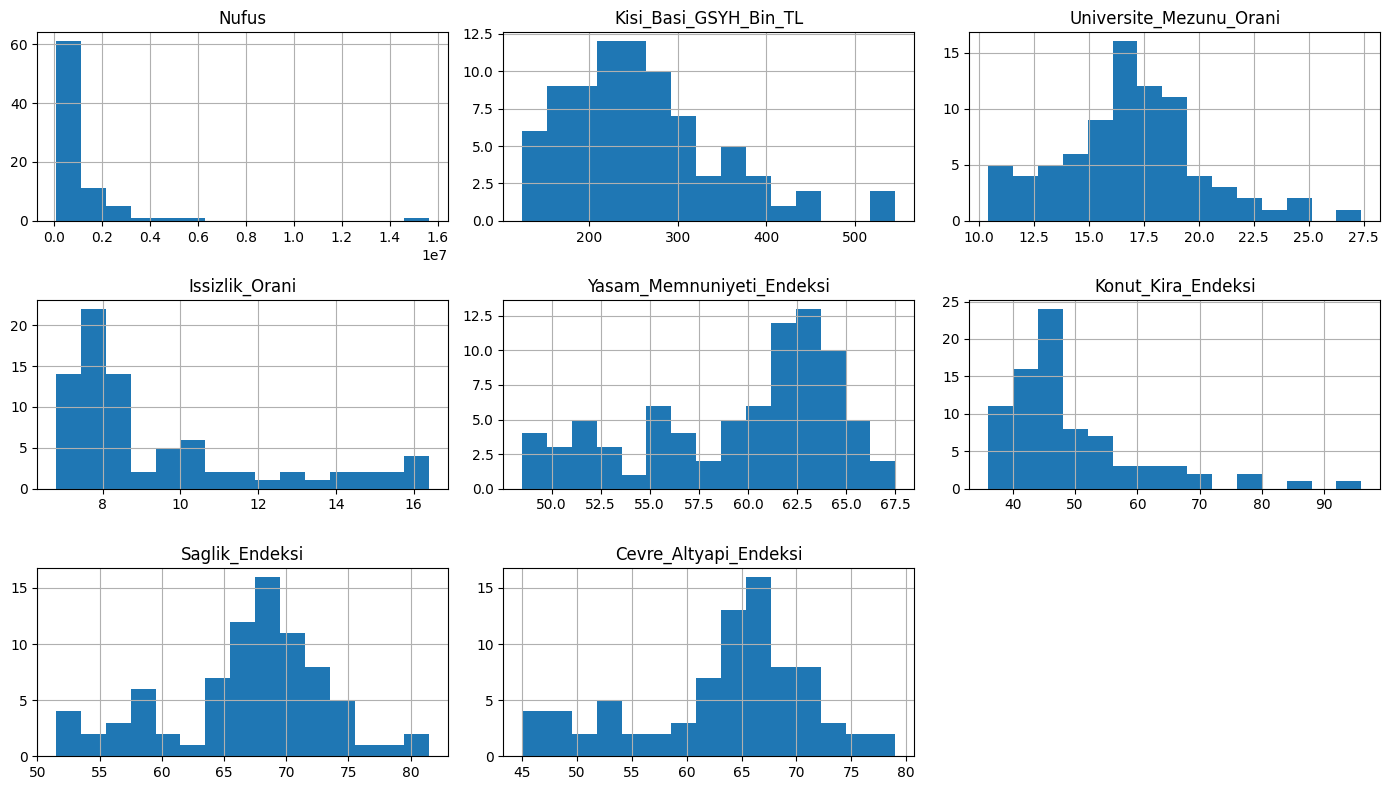

Nüfus çarpıklığı (önce): 6.08564964550575
Nüfus çarpıklığı (sonra): 0.6133664803731302


In [6]:
df_temiz[ozellikler].hist(bins=15, figsize=(14, 8))
plt.tight_layout(); plt.show()

print("Nüfus çarpıklığı (önce):", df_temiz["Nufus"].skew())
df_temiz["Nufus_log"] = np.log1p(df_temiz["Nufus"])
print("Nüfus çarpıklığı (sonra):", df_temiz["Nufus_log"].skew())

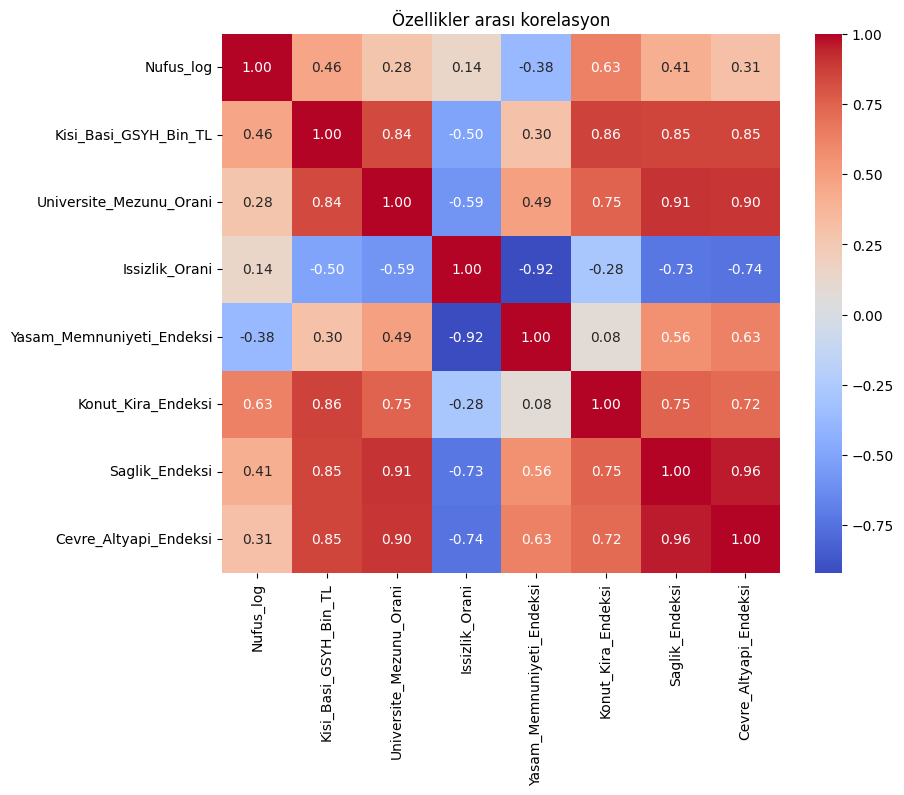

In [7]:
kullanilacak = ["Nufus_log", "Kisi_Basi_GSYH_Bin_TL", "Universite_Mezunu_Orani",
                "Issizlik_Orani", "Yasam_Memnuniyeti_Endeksi", "Konut_Kira_Endeksi",
                "Saglik_Endeksi", "Cevre_Altyapi_Endeksi"]

plt.figure(figsize=(9, 7))
sns.heatmap(df_temiz[kullanilacak].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Özellikler arası korelasyon")
plt.show()

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_temiz[kullanilacak])

print(X_scaled.shape)
print("Ortalama ≈ 0:", X_scaled.mean(axis=0).round(2))
print("Std ≈ 1:", X_scaled.std(axis=0).round(2))

(81, 8)
Ortalama ≈ 0: [ 0. -0.  0.  0. -0. -0. -0.  0.]
Std ≈ 1: [1. 1. 1. 1. 1. 1. 1. 1.]


In [10]:
# Kmeans ve k sayısı belirleme
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_araligi = range(2, 11)
inertia = []
silhouette = []

for k in k_araligi:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiketler = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, etiketler))

sonuc = pd.DataFrame({"k": list(k_araligi), "inertia": inertia, "silhouette": silhouette})
print(sonuc.round(3))

    k  inertia  silhouette
0   2  347.107       0.468
1   3  216.987       0.459
2   4  167.827       0.374
3   5  138.747       0.366
4   6  118.617       0.360
5   7  105.994       0.358
6   8   93.289       0.299
7   9   86.269       0.296
8  10   78.493       0.290


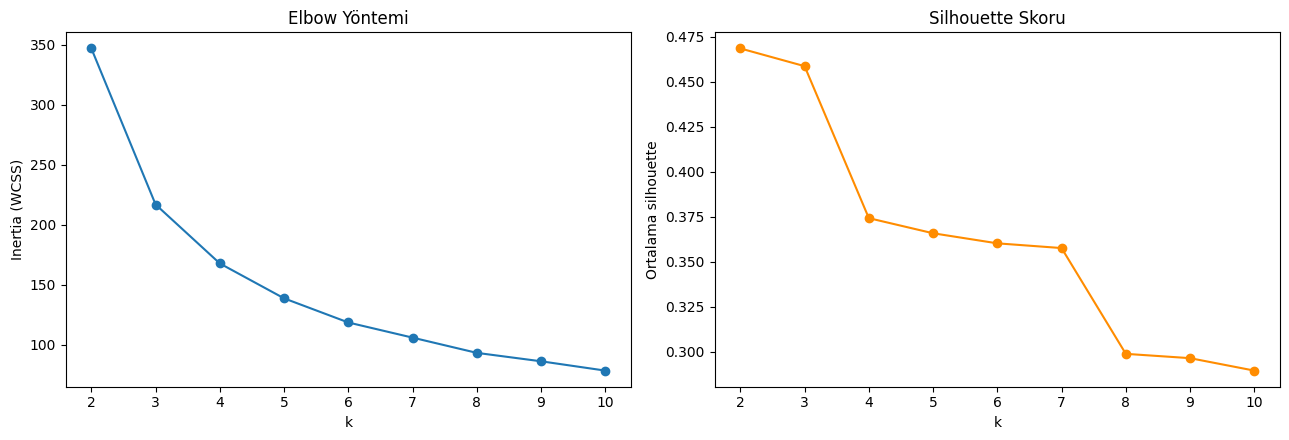

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(sonuc["k"], sonuc["inertia"], marker="o")
ax[0].set_title("Elbow Yöntemi")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia (WCSS)")

ax[1].plot(sonuc["k"], sonuc["silhouette"], marker="o", color="darkorange")
ax[1].set_title("Silhouette Skoru")
ax[1].set_xlabel("k"); ax[1].set_ylabel("Ortalama silhouette")

plt.tight_layout(); plt.show()

In [12]:
k_secilen = 3

kmeans = KMeans(n_clusters=k_secilen, n_init=10, random_state=42)
df_temiz["KMeans_Kume"] = kmeans.fit_predict(X_scaled)

print(df_temiz["KMeans_Kume"].value_counts().sort_index())
print("Silhouette:", round(silhouette_score(X_scaled, df_temiz["KMeans_Kume"]), 3))

KMeans_Kume
0    10
1    53
2    18
Name: count, dtype: int64
Silhouette: 0.459


In [13]:
ozet = df_temiz.groupby("KMeans_Kume")[ozellikler].mean().round(1)
print(ozet)

for k in range(k_secilen):
    sehirler = df_temiz.loc[df_temiz["KMeans_Kume"] == k, "Sehir"].tolist()
    print(f"\nKüme {k} ({len(sehirler)} şehir):", ", ".join(sehirler))

                 Nufus  Kisi_Basi_GSYH_Bin_TL  Universite_Mezunu_Orani  \
KMeans_Kume                                                              
0            3740665.1                  427.0                     22.2   
1             672112.2                  261.5                     17.4   
2             685765.4                  163.8                     12.6   

             Issizlik_Orani  Yasam_Memnuniyeti_Endeksi  Konut_Kira_Endeksi  \
KMeans_Kume                                                                  
0                       8.8                       58.8                71.0   
1                       8.1                       62.1                48.0   
2                      13.7                       52.4                40.1   

             Saglik_Endeksi  Cevre_Altyapi_Endeksi  
KMeans_Kume                                         
0                      75.8                   74.3  
1                      68.4                   65.4  
2                      56.

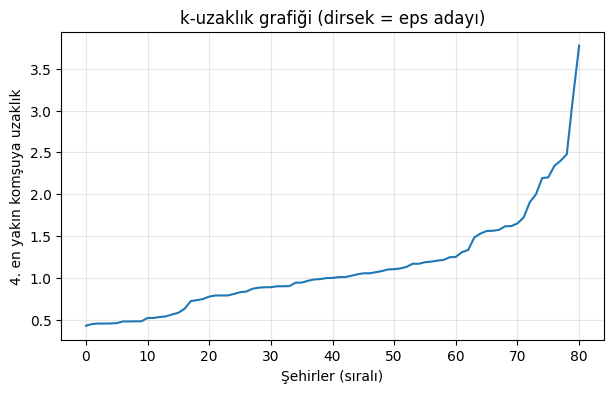

In [14]:
#DBSCAN 
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

min_samples = 4
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
uzakliklar, _ = nn.kneighbors(X_scaled)
k_uzaklik = np.sort(uzakliklar[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(k_uzaklik)
plt.xlabel("Şehirler (sıralı)")
plt.ylabel(f"{min_samples}. en yakın komşuya uzaklık")
plt.title("k-uzaklık grafiği (dirsek = eps adayı)")
plt.grid(alpha=0.3)
plt.show()

In [15]:
satirlar = []
for eps in [0.8, 1.0, 1.2, 1.4, 1.6]:
    for ms in [3, 4, 5]:
        et = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        kume_sayisi = len(set(et)) - (1 if -1 in et else 0)
        maske = et != -1
        sil = silhouette_score(X_scaled[maske], et[maske]) if kume_sayisi > 1 else np.nan
        satirlar.append([eps, ms, kume_sayisi, (et == -1).sum(), sil])

dbscan_sonuc = pd.DataFrame(satirlar, columns=["eps", "min_samples", "küme_sayısı", "gürültü", "silhouette"])
print(dbscan_sonuc.round(3))

    eps  min_samples  küme_sayısı  gürültü  silhouette
0   0.8            3            6       37       0.444
1   0.8            4            2       50       0.519
2   0.8            5            2       51       0.526
3   1.0            3            5       22       0.351
4   1.0            4            6       23       0.381
5   1.0            5            3       36       0.499
6   1.2            3            2       17       0.591
7   1.2            4            2       17       0.591
8   1.2            5            2       19       0.596
9   1.4            3            3       12       0.392
10  1.4            4            2       15       0.584
11  1.4            5            2       15       0.584
12  1.6            3            1        9         NaN
13  1.6            4            1        9         NaN
14  1.6            5            2       11       0.555


In [16]:
dbscan = DBSCAN(eps=1.2, min_samples=4)
df_temiz["DBSCAN_Kume"] = dbscan.fit_predict(X_scaled)

print(df_temiz["DBSCAN_Kume"].value_counts().sort_index())
print("\nGürültü olarak işaretlenen şehirler:")
print(df_temiz.loc[df_temiz["DBSCAN_Kume"] == -1, "Sehir"].tolist())

DBSCAN_Kume
-1    17
 0    49
 1    15
Name: count, dtype: int64

Gürültü olarak işaretlenen şehirler:
['Adana', 'Ankara', 'Antalya', 'Bursa', 'Diyarbakır', 'Eskişehir', 'Gaziantep', 'Hatay', 'Mersin', 'İstanbul', 'İzmir', 'Kocaeli', 'Mardin', 'Muğla', 'Tekirdağ', 'Tunceli', 'Yalova']


In [ ]:
#GMM

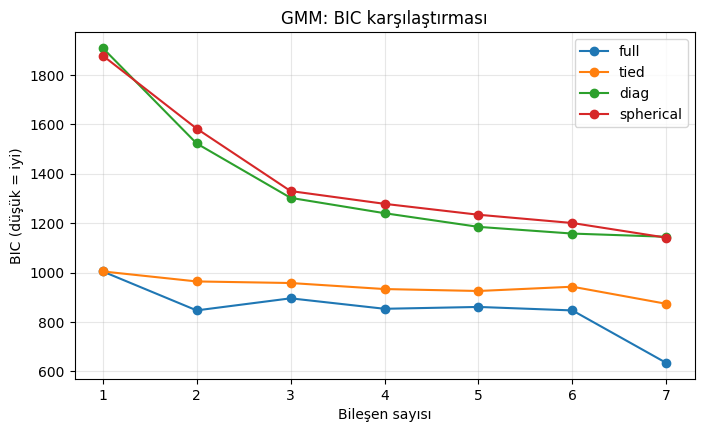

In [17]:
from sklearn.mixture import GaussianMixture

n_araligi = range(1, 8)
cov_tipleri = ["full", "tied", "diag", "spherical"]
bic_tablo = {}

for ct in cov_tipleri:
    bic_tablo[ct] = [
        GaussianMixture(n_components=n, covariance_type=ct, n_init=10, random_state=42).fit(X_scaled).bic(X_scaled)
        for n in n_araligi
    ]

plt.figure(figsize=(8, 4.5))
for ct in cov_tipleri:
    plt.plot(list(n_araligi), bic_tablo[ct], marker="o", label=ct)
plt.xlabel("Bileşen sayısı"); plt.ylabel("BIC (düşük = iyi)")
plt.title("GMM: BIC karşılaştırması"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [18]:
gmm = GaussianMixture(n_components=3, covariance_type="tied", n_init=10, random_state=42)
df_temiz["GMM_Kume"] = gmm.fit_predict(X_scaled)

print(df_temiz["GMM_Kume"].value_counts().sort_index())
print("Silhouette:", round(silhouette_score(X_scaled, df_temiz["GMM_Kume"]), 3))
print("BIC:", round(gmm.bic(X_scaled), 1))

# GMM'ye özgü: her şehrin kümeye ait olma olasılığı
olasiliklar = gmm.predict_proba(X_scaled)
df_temiz["GMM_Guven"] = olasiliklar.max(axis=1)
print("\nEn belirsiz 5 şehir:")
print(df_temiz.nsmallest(5, "GMM_Guven")[["Sehir", "GMM_Kume", "GMM_Guven"]])

GMM_Kume
0    61
1     7
2    13
Name: count, dtype: int64
Silhouette: 0.426
BIC: 957.5

En belirsiz 5 şehir:
        Sehir  GMM_Kume  GMM_Guven
11     Bingöl         2   0.909663
15      Bursa         0   0.915123
16  Çanakkale         0   0.966972
58   Tekirdağ         1   0.973419
8       Aydın         0   0.978256


3 yöntemin karşılaştırılması


In [19]:
from sklearn.metrics import adjusted_rand_score

print("K-Means vs GMM   ARI:", round(adjusted_rand_score(df_temiz["KMeans_Kume"], df_temiz["GMM_Kume"]), 3))
print("K-Means vs DBSCAN ARI:", round(adjusted_rand_score(df_temiz["KMeans_Kume"], df_temiz["DBSCAN_Kume"]), 3))

print(pd.crosstab(df_temiz["KMeans_Kume"], df_temiz["GMM_Kume"], rownames=["KMeans"], colnames=["GMM"]))

K-Means vs GMM   ARI: 0.678
K-Means vs DBSCAN ARI: 0.8
GMM      0  1   2
KMeans           
0        3  7   0
1       53  0   0
2        5  0  13


tablolar

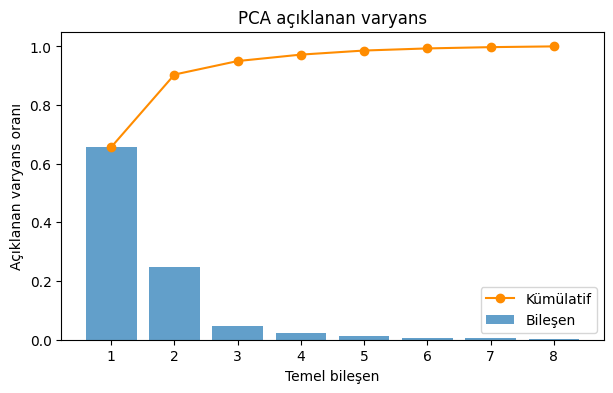

İlk 2 bileşen toplamı: 0.904


In [20]:
from sklearn.decomposition import PCA

pca_tam = PCA(random_state=42).fit(X_scaled)
oran = pca_tam.explained_variance_ratio_

plt.figure(figsize=(7, 4))
plt.bar(range(1, 9), oran, alpha=0.7, label="Bileşen")
plt.plot(range(1, 9), oran.cumsum(), marker="o", color="darkorange", label="Kümülatif")
plt.xlabel("Temel bileşen"); plt.ylabel("Açıklanan varyans oranı")
plt.title("PCA açıklanan varyans"); plt.legend(); plt.show()

print("İlk 2 bileşen toplamı:", round(oran[:2].sum(), 3))

In [21]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
df_temiz["PC1"], df_temiz["PC2"] = X_pca[:, 0], X_pca[:, 1]

yukler = pd.DataFrame(pca.components_.T, index=kullanilacak, columns=["PC1", "PC2"]).round(2)
print(yukler)

                            PC1   PC2
Nufus_log                  0.16  0.58
Kisi_Basi_GSYH_Bin_TL      0.40  0.18
Universite_Mezunu_Orani    0.40  0.02
Issizlik_Orani            -0.32  0.43
Yasam_Memnuniyeti_Endeksi  0.26 -0.56
Konut_Kira_Endeksi         0.35  0.36
Saglik_Endeksi             0.43  0.01
Cevre_Altyapi_Endeksi      0.43 -0.05


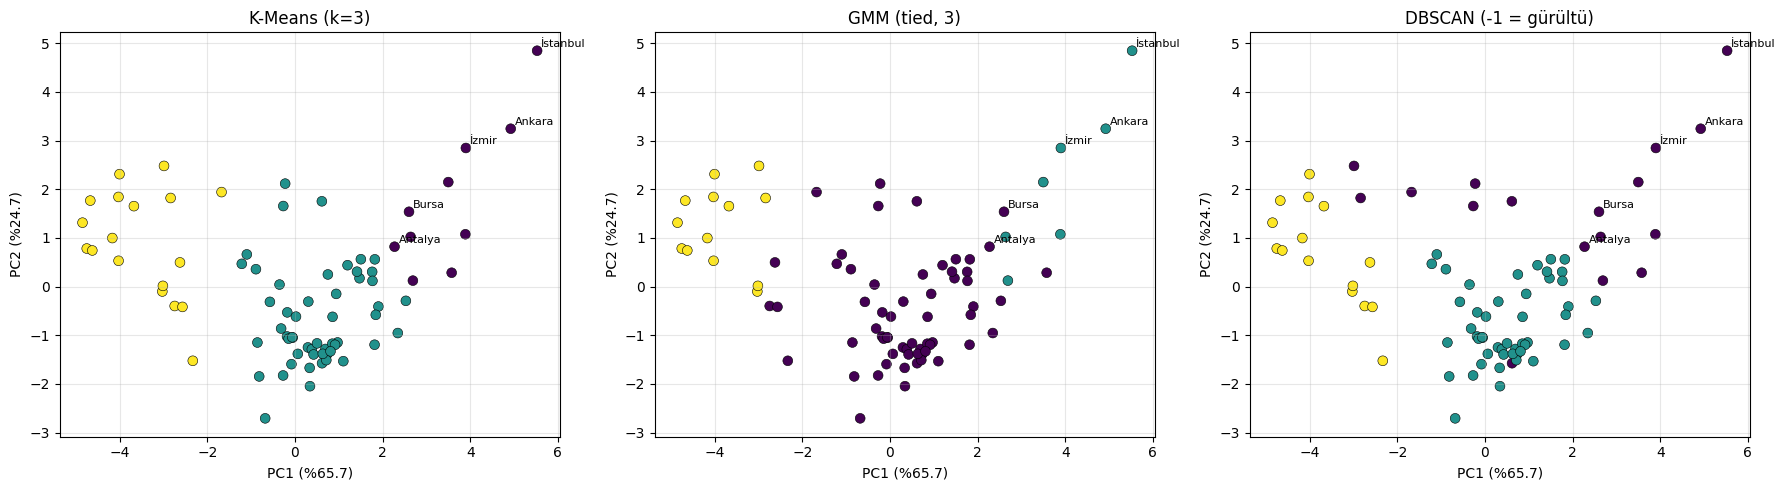

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
basliklar = {"KMeans_Kume": "K-Means (k=3)", "GMM_Kume": "GMM (tied, 3)", "DBSCAN_Kume": "DBSCAN (-1 = gürültü)"}

for a, (sutun, baslik) in zip(ax, basliklar.items()):
    sc = a.scatter(df_temiz["PC1"], df_temiz["PC2"], c=df_temiz[sutun], cmap="viridis", s=50, edgecolor="k", linewidth=0.4)
    a.set_title(baslik)
    a.set_xlabel(f"PC1 (%{oran[0]*100:.1f})"); a.set_ylabel(f"PC2 (%{oran[1]*100:.1f})")
    a.grid(alpha=0.3)

    # büyük şehirleri etiketle
    for _, r in df_temiz[df_temiz["Nufus"] > 2_500_000].iterrows():
        a.annotate(r["Sehir"], (r["PC1"], r["PC2"]), fontsize=8, xytext=(3, 3), textcoords="offset points")

plt.tight_layout(); plt.show()

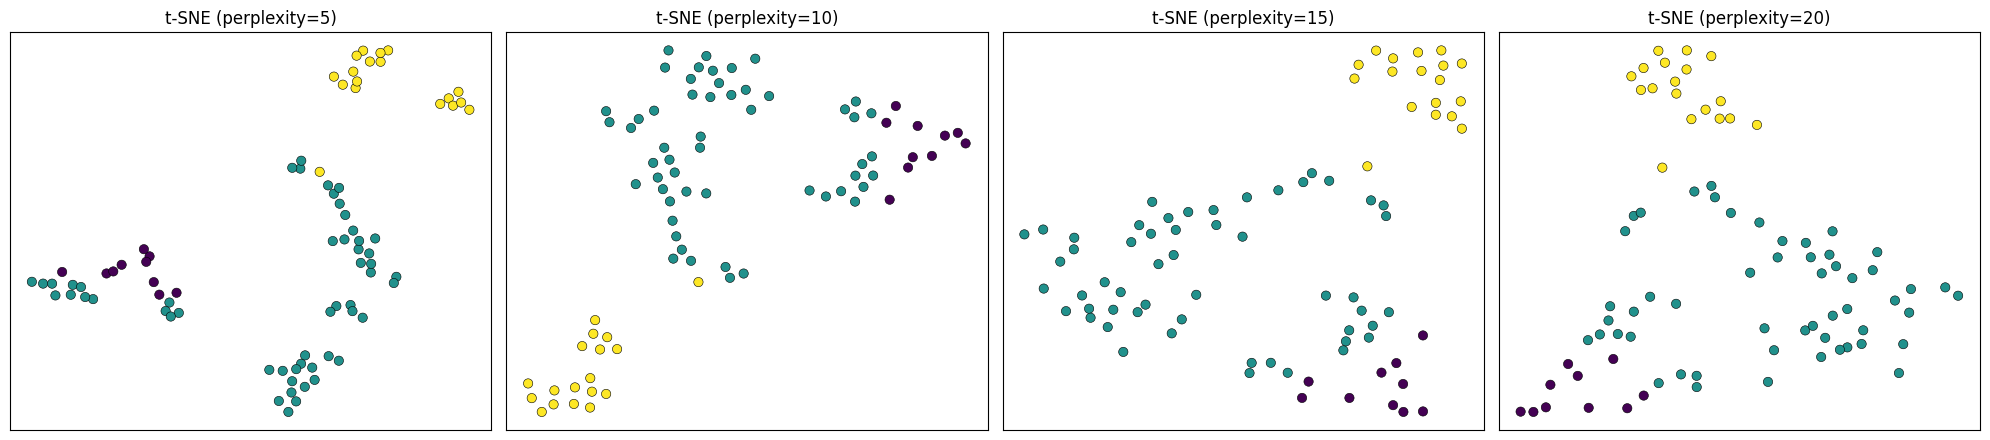

In [23]:
from sklearn.manifold import TSNE

perplexities = [5, 10, 15, 20]
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))

for a, p in zip(ax, perplexities):
    emb = TSNE(n_components=2, perplexity=p, init="pca", learning_rate="auto", random_state=42).fit_transform(X_scaled)
    a.scatter(emb[:, 0], emb[:, 1], c=df_temiz["KMeans_Kume"], cmap="viridis", s=45, edgecolor="k", linewidth=0.4)
    a.set_title(f"t-SNE (perplexity={p})")
    a.set_xticks([]); a.set_yticks([])

plt.tight_layout(); plt.show()

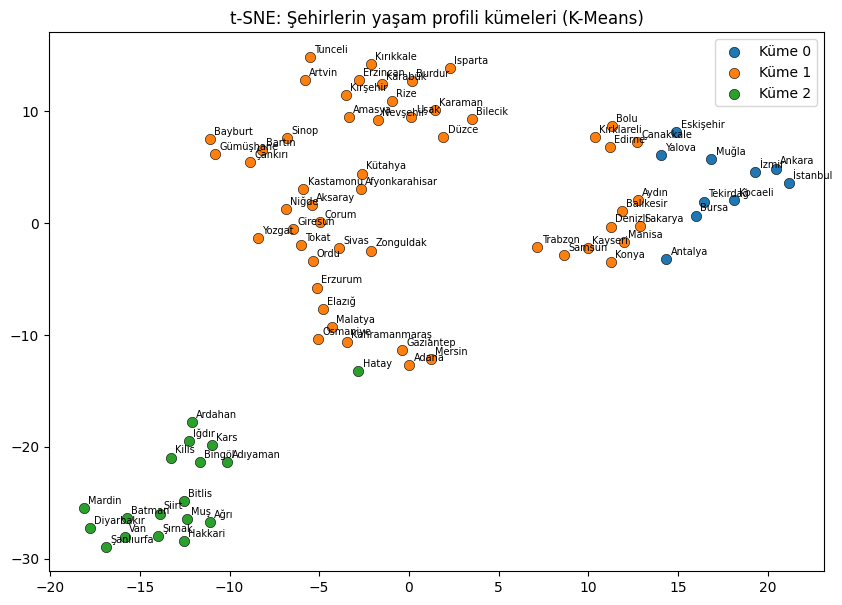

In [24]:
perp_secilen = 10   # grafiğe bakıp değiştirebilirsiniz
emb = TSNE(n_components=2, perplexity=perp_secilen, init="pca", learning_rate="auto", random_state=42).fit_transform(X_scaled)
df_temiz["TSNE1"], df_temiz["TSNE2"] = emb[:, 0], emb[:, 1]

plt.figure(figsize=(10, 7))
for k in sorted(df_temiz["KMeans_Kume"].unique()):
    alt = df_temiz[df_temiz["KMeans_Kume"] == k]
    plt.scatter(alt["TSNE1"], alt["TSNE2"], s=55, edgecolor="k", linewidth=0.4, label=f"Küme {k}")
for _, r in df_temiz.iterrows():
    plt.annotate(r["Sehir"], (r["TSNE1"], r["TSNE2"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.title("t-SNE: Şehirlerin yaşam profili kümeleri (K-Means)")
plt.legend(); plt.show()